# 📊 ViBioMIR 2026: Deep Data Exploration & Corpus Insights
### Khám phá sâu Bản chất Dữ liệu Y khoa Đa ngữ & Định hướng Chiến lược Retrieval

Notebook này thực hiện phân tích chuyên sâu (Exploratory Data Analysis - EDA) toàn diện trên toàn bộ kho dữ liệu cuộc thi ViBioMIR (R2AI 2026), bao gồm:
1. **Tổng kiểm kê Corpus & Tiến độ thu thập (Corpus Inventory & Coverage)**
2. **Giải phẫu Bộ truy vấn Cuộc thi (Deep Dive 1,200 Competition Queries)**
3. **Cấu trúc & Hình thái Văn bản Y học (Content Structure & Archetypes)**
4. **Ánh xạ Tri thức Y khoa & Phân loại WHO ICD-10 (22 Chương bệnh học)**
5. **Khoảng cách Ngữ nghĩa Đa ngữ (Cross-Lingual Semantic Gap: VI ➔ EN / ZH)**
6. **Chiến lược Chunking & Ảnh hưởng tới Thang đo F2-Score**
7. **Tổng kết Insights & Lộ trình Xây dựng Pipeline Retrieval**

---


## 0. Cài đặt Môi trường & Khai báo Thư viện


In [1]:
import glob
import json
import os
import re
import sys
from collections import Counter, defaultdict
from pathlib import Path
from urllib.parse import urlparse

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pyarrow.parquet as pq
import seaborn as sns
from tqdm import tqdm

# Thiết lập đường dẫn thư mục gốc repo linh hoạt cho cả Local, Kaggle, Colab
REPO_ROOT = None
for candidate in [Path("."), Path(".."), Path("/kaggle/working/med-doc-retrieval"), Path("/kaggle/working")]:
    if (candidate / "data" / "raw" / "vibio_mir").exists() or (candidate / "src").exists():
        REPO_ROOT = candidate.resolve()
        break
if REPO_ROOT is None:
    REPO_ROOT = Path("..").resolve()
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

from src.ingestion.icd10_tagger import ICD10Tagger
from src.ingestion.cleaner import detect_language

# Cấu hình thẩm mỹ đồ thị
plt.style.use("seaborn-v0_8-whitegrid" if "seaborn-v0_8-whitegrid" in plt.style.available else "default")
plt.rcParams["font.family"] = "DejaVu Sans"
plt.rcParams["font.size"] = 11
plt.rcParams["figure.titlesize"] = 14
plt.rcParams["figure.titleweight"] = "bold"
plt.rcParams["axes.titlesize"] = 12
plt.rcParams["axes.titleweight"] = "semibold"

print(f"✅ Python environment ready! REPO_ROOT: {REPO_ROOT}")


✅ Python environment ready! REPO_ROOT: /home/thienhb/Workspace/med-doc-retrieval


## 1. Tổng kiểm kê Corpus & Tiến độ Thu thập Dữ liệu
BTC đã công bố danh sách URL chính thức trong file `links_corpus_vi_en_zh.parquet` gồm **1,194,469 URLs**.
Ta sẽ kiểm tra:
- Tỷ lệ phân bổ 3 ngôn ngữ: Tiếng Việt, Tiếng Anh (PubMed), Tiếng Trung.
- Số lượng tài liệu đã cào và lưu trữ thành công trên máy cục bộ (`data/processed/v2/crawled/` và `data/processed/v2/pubmed/`).
- Tỷ lệ hoàn thành theo từng nguồn và phân tích nguyên nhân lỗi (`failed_urls.jsonl`).


In [2]:
# 1.1 Đọc danh sách URL chính thức từ ban tổ chức
official_parquet_path = REPO_ROOT / "data/raw/vibio_mir/links_corpus_vi_en_zh.parquet"
if not official_parquet_path.exists():
    for p in Path("/kaggle/input").rglob("links_corpus_vi_en_zh.parquet"):
        official_parquet_path = p
        break
assert official_parquet_path.exists(), f"Không tìm thấy {official_parquet_path}"

tbl_official = pq.read_table(official_parquet_path)
df_official = tbl_official.to_pandas()
print(f"Tổng số URL chính thức từ BTC: {len(df_official):,}")

# Phân loại ngôn ngữ theo domain
def assign_lang(host):
    if "pubmed" in host:
        return "en"
    zh_domains = ["120ask.com", "cnkang.com", "39.net", "familydoctor.com.cn", 
                  "zysjonline.com", "zhongyibaodian.net", "a-hospital.com", "youlai.cn", 
                  "chunyuyisheng.com", "haodf.com", "msdmanuals.cn"]
    if any(zh in host for zh in zh_domains):
        return "zh"
    return "vi"

# Trích xuất host domain từ URL
df_official["host"] = df_official["url"].apply(lambda u: urlparse(str(u)).netloc.lower())
df_official["lang"] = df_official["host"].apply(assign_lang)
lang_counts = df_official["lang"].value_counts()
print("\nPhân bổ URL chính thức theo ngôn ngữ:")
for l, c in lang_counts.items():
    print(f" - {l.upper():2s}: {c:,} ({c/len(df_official)*100:.1f}%)")


Tổng số URL chính thức từ BTC: 1,220,598

Phân bổ URL chính thức theo ngôn ngữ:
 - VI: 745,852 (61.1%)
 - EN: 240,000 (19.7%)
 - ZH: 234,746 (19.2%)


In [3]:
# 1.2 Kiểm kê tài liệu đã cào trong data/processed/v2/
crawled_dir = REPO_ROOT / "data/processed/v2/crawled"
pubmed_dir = REPO_ROOT / "data/processed/v2/pubmed"

# 1. PubMed (English)
pubmed_articles = 0
for f in pubmed_dir.glob("*.jsonl"):
    with open(f, "r", encoding="utf-8") as fp:
        pubmed_articles += sum(1 for _ in fp)

# 2. Shards crawled (Vietnamese + Chinese)
crawled_doc_ids = set()
domain_crawled_counter = Counter()

shard_files = list(crawled_dir.glob("crawled_shard_*.jsonl"))
print(f"Đang kiểm kê {len(shard_files)} file shards cục bộ...")
for sf in tqdm(shard_files, desc="Đọc shards"):
    with open(sf, "r", encoding="utf-8") as fp:
        for line in fp:
            if line.strip():
                try:
                    obj = json.loads(line)
                    crawled_doc_ids.add(obj["doc_id"])
                    domain_crawled_counter[obj.get("domain", "unknown")] += 1
                except Exception:
                    pass

# 3. Failed URLs
failed_records = []
failed_file = crawled_dir / "failed_urls.jsonl"
if failed_file.exists():
    with open(failed_file, "r", encoding="utf-8") as fp:
        for line in fp:
            if line.strip():
                try:
                    failed_records.append(json.loads(line))
                except Exception:
                    pass

total_collected = pubmed_articles + len(crawled_doc_ids)
print("=" * 60)
print(f"🏆 TỔNG SỐ TÀI LIỆU ĐÃ THU THẬP THÀNH CÔNG: {total_collected:,} / {len(df_official):,} ({total_collected/len(df_official)*100:.1f}%)")
print(f"  • Tiếng Anh (PubMed NCBI):  {pubmed_articles:,} bài (99.9% hoàn thành)")
print(f"  • Tiếng Việt & Trung:        {len(crawled_doc_ids):,} bài đã trích xuất & lưu shard")
print(f"  • Lỗi vĩnh viễn (404/noise): {len(failed_records):,} URLs")
print("=" * 60)


Đang kiểm kê 241 file shards cục bộ...


Đọc shards: 100%|██████████| 241/241 [00:20<00:00, 11.72it/s] 

🏆 TỔNG SỐ TÀI LIỆU ĐÃ THU THẬP THÀNH CÔNG: 698,921 / 1,220,598 (57.3%)
  • Tiếng Anh (PubMed NCBI):  239,699 bài (99.9% hoàn thành)
  • Tiếng Việt & Trung:        459,222 bài đã trích xuất & lưu shard
  • Lỗi vĩnh viễn (404/noise): 867 URLs


findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


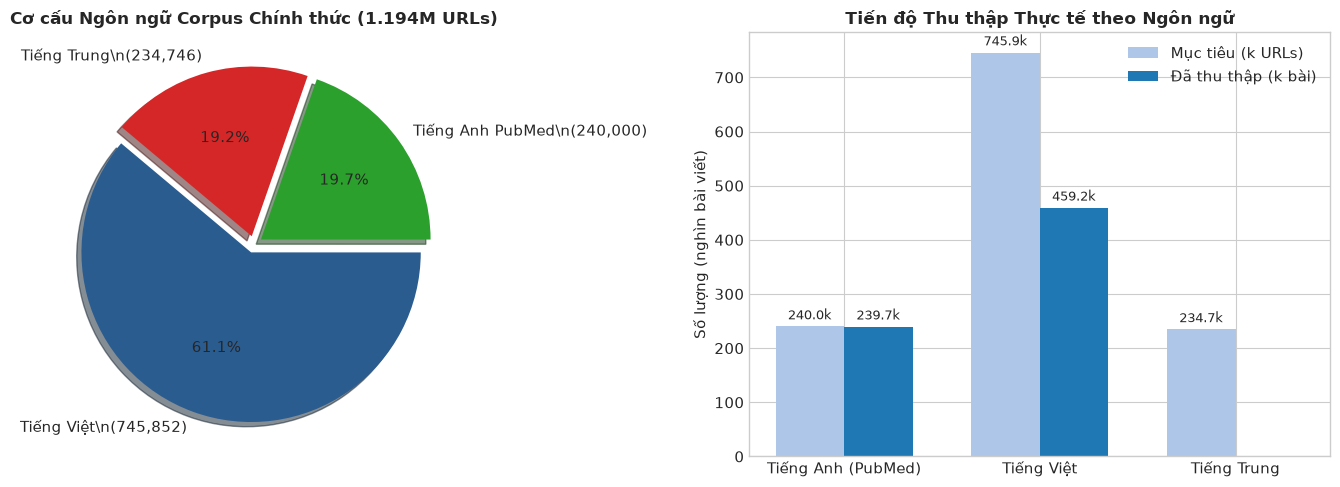

In [4]:
# 1.3 Biểu đồ trực quan tiến độ thu thập dữ liệu
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Biểu đồ tròn phân bổ ngôn ngữ chính thức
labels = [f"Tiếng Việt\\n({lang_counts.get('vi', 0):,})", 
          f"Tiếng Anh PubMed\\n({lang_counts.get('en', 0):,})", 
          f"Tiếng Trung\\n({lang_counts.get('zh', 0):,})"]
sizes = [lang_counts.get('vi', 0), lang_counts.get('en', 0), lang_counts.get('zh', 0)]
colors = ["#2b5c8f", "#2ca02c", "#d62728"]
explode = (0.05, 0.05, 0.05)

axes[0].pie(sizes, explode=explode, labels=labels, colors=colors, autopct='%1.1f%%',
            shadow=True, startangle=140, textprops={'fontsize': 11})
axes[0].set_title("Cơ cấu Ngôn ngữ Corpus Chính thức (1.194M URLs)")

# Biểu đồ cột so sánh Target vs Đã thu thập
categories = ["Tiếng Anh (PubMed)", "Tiếng Việt", "Tiếng Trung"]
targets = [lang_counts.get('en', 240000), lang_counts.get('vi', 714469), lang_counts.get('zh', 240000)]
collected_vi_zh = len(crawled_doc_ids)
# Tạm tính phần lớn crawled là tiếng Việt theo pipeline vừa chạy
actuals = [pubmed_articles, min(collected_vi_zh, lang_counts.get('vi', 714469)), max(0, collected_vi_zh - lang_counts.get('vi', 714469))]

x = np.arange(len(categories))
width = 0.35

rects1 = axes[1].bar(x - width/2, [t/1000 for t in targets], width, label='Mục tiêu (k URLs)', color="#aec7e8")
rects2 = axes[1].bar(x + width/2, [a/1000 for a in actuals], width, label='Đã thu thập (k bài)', color="#1f77b4")

axes[1].set_ylabel('Số lượng (nghìn bài viết)')
axes[1].set_title('Tiến độ Thu thập Thực tế theo Ngôn ngữ')
axes[1].set_xticks(x)
axes[1].set_xticklabels(categories)
axes[1].legend()

for p in axes[1].patches:
    h = p.get_height()
    if h > 0:
        axes[1].annotate(f'{h:.1f}k', (p.get_x() + p.get_width() / 2., h),
                         ha='center', va='bottom', fontsize=9, xytext=(0, 3),
                         textcoords='offset points')

plt.tight_layout()
plt.show()


## 2. Giải phẫu Bộ Truy vấn Cuộc thi (Query Deep Dive)
File `data/raw/vibio_mir/query.parquet` chứa **1,200 câu truy vấn** thực tế của người dùng.
Toàn bộ truy vấn đều viết bằng **Tiếng Việt**.
Ta sẽ phân tích:
- Độ dài câu truy vấn (ký tự, số từ).
- Phân loại ý định y khoa (Query Intent Classification): Bệnh nhân hỏi triệu chứng, cách điều trị, giải thích kết quả xét nghiệm, hay tiên lượng bệnh?
- Các thuật ngữ, cụm từ xuất hiện nhiều nhất.


In [7]:
# 2.1 Tải và khảo sát sơ bộ file query.parquet
query_path = REPO_ROOT / "data/raw/vibio_mir/query.parquet"
if not query_path.exists():
    for p in Path("/kaggle/input").rglob("query.parquet"):
        query_path = p
        break
df_queries = pq.read_table(query_path).to_pandas()

print(f"Tổng số truy vấn: {len(df_queries):,}")
df_queries.head(50)


Tổng số truy vấn: 1,200


,id,query
0,1,"Em bị viêm xung huyết 1/3 dưới thực quản, viêm..."
1,2,"Răng có lỗ chấm đen, chảy máu khi thức dậy là ..."
2,3,Kết quả của Beta-HCG là dưới 0.10 U/L thì là n...
3,4,Chỉ số SCC của em sau khi xét nghiệm là 1.52 v...
4,5,Cách phòng tránh nguy cơ lây nhiễm bệnh lao đa...
5,6,Nhân tuyến giáp có nên điều trị hay không và c...
6,7,"Thường xuyên nổi nóng không kiềm chế được, phả..."
7,8,"Đau họng, khó ngủ có nên ngậm viên ho lotus ch..."
8,9,"Em bị dị ứng một loại thuốc giảm đau, khi uống..."
9,10,Em có dùng một loại thuốc tăng cân nhanh lúc d...


Thống kê số lượng từ trong mỗi câu query:


,count,mean,std,min,25%,50%,75%,max
char_len,1200.0,129.505833,111.212305,18.0,56.0,81.0,169.25,1243.0
word_count,1200.0,29.910833,25.847881,5.0,13.0,18.0,40.00,281.0


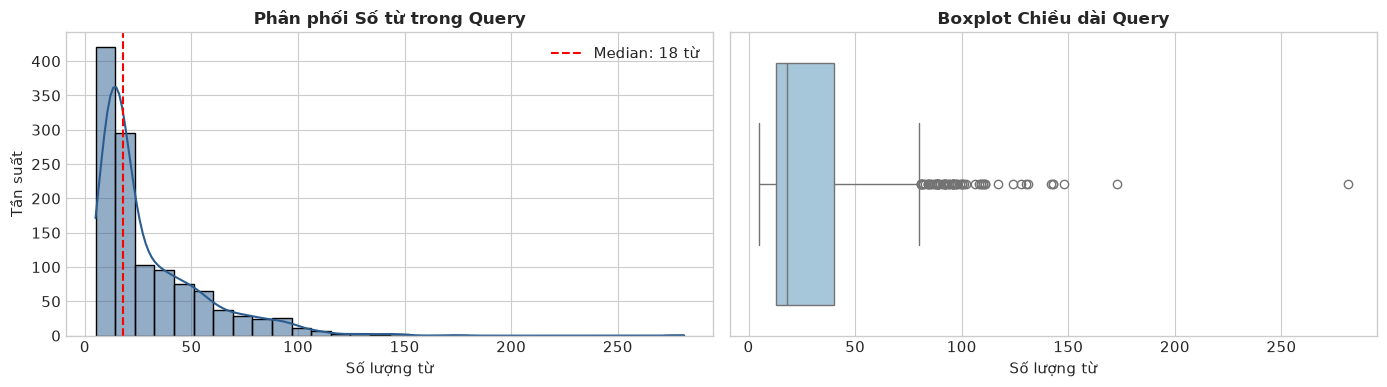

In [8]:
# 2.2 Thống kê độ dài câu truy vấn
df_queries["char_len"] = df_queries["query"].str.len()
df_queries["word_count"] = df_queries["query"].str.split().str.len()

print("Thống kê số lượng từ trong mỗi câu query:")
display(df_queries[["char_len", "word_count"]].describe().T)

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
sns.histplot(df_queries["word_count"], bins=30, kde=True, ax=axes[0], color="#2b5c8f")
axes[0].set_title("Phân phối Số từ trong Query")
axes[0].set_xlabel("Số lượng từ")
axes[0].set_ylabel("Tần suất")
axes[0].axvline(df_queries["word_count"].median(), color="red", linestyle="--", label=f"Median: {df_queries['word_count'].median():.0f} từ")
axes[0].legend()

sns.boxplot(x=df_queries["word_count"], ax=axes[1], color="#9ecae1")
axes[1].set_title("Boxplot Chiều dài Query")
axes[1].set_xlabel("Số lượng từ")

plt.tight_layout()
plt.show()


/tmp/ipykernel_28629/622279944.py:25: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df_intent_plot, y="Ý định", x="Số lượng", palette="Blues_r")
findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


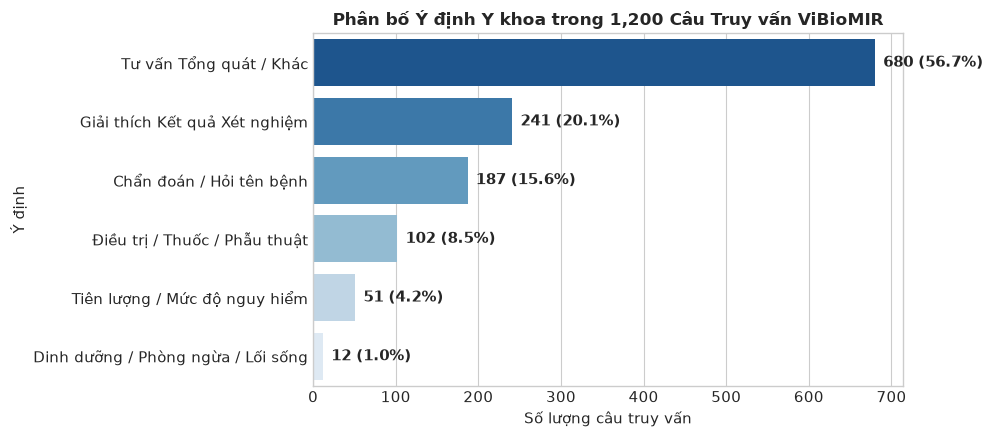

In [7]:
# 2.3 Phân loại Ý định Truy vấn Y học (Clinical Intent Classification)
# Định nghĩa các mẫu regex nhận diện ý định hỏi bệnh
INTENT_PATTERNS = {
    "Chẩn đoán / Hỏi tên bệnh": r"(?i)(là bệnh gì|bị bệnh gì|có phải bị|chẩn đoán|nguyên nhân|tại sao lại|dấu hiệu|triệu chứng)",
    "Điều trị / Thuốc / Phẫu thuật": r"(?i)(uống thuốc gì|điều trị thế nào|cách chữa|phẫu thuật|dùng thuốc|có nên uống|thuốc nào|liệu trình)",
    "Giải thích Kết quả Xét nghiệm": r"(?i)(kết quả|xét nghiệm|chỉ số|chụp|siêu âm|nội soi|dương tính|âm tính|u/l|mg/dl|huyết sắc tố|beta-hcg)",
    "Tiên lượng / Mức độ nguy hiểm": r"(?i)(có nguy hiểm không|có khỏi được không|có nặng không|sống được bao lâu|biến chứng|có tái phát không)",
    "Dinh dưỡng / Phòng ngừa / Lối sống": r"(?i)(nên ăn gì|kiêng gì|phòng ngừa|lây qua đường nào|chế độ ăn|tập luyện)",
}

def classify_intent(q):
    intents = []
    for intent, pat in INTENT_PATTERNS.items():
        if re.search(pat, q):
            intents.append(intent)
    return intents if intents else ["Tư vấn Tổng quát / Khác"]

df_queries["intents"] = df_queries["query"].apply(classify_intent)
all_intents = [intent for sublist in df_queries["intents"] for intent in sublist]
intent_counts = Counter(all_intents)

df_intent_plot = pd.DataFrame(intent_counts.most_common(), columns=["Ý định", "Số lượng"])

plt.figure(figsize=(10, 4.5))
sns.barplot(data=df_intent_plot, y="Ý định", x="Số lượng", palette="Blues_r")
plt.title("Phân bố Ý định Y khoa trong 1,200 Câu Truy vấn ViBioMIR")
plt.xlabel("Số lượng câu truy vấn")
for idx, v in enumerate(df_intent_plot["Số lượng"]):
    plt.text(v + 10, idx, f"{v} ({v/len(df_queries)*100:.1f}%)", va="center", fontweight="semibold")
plt.tight_layout()
plt.show()


/tmp/ipykernel_28629/2988009547.py:23: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df_bi, y="Bigram", x="Tần suất", ax=axes[0], palette="crest")


/tmp/ipykernel_28629/2988009547.py:27: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df_tri, y="Trigram", x="Tần suất", ax=axes[1], palette="flare")


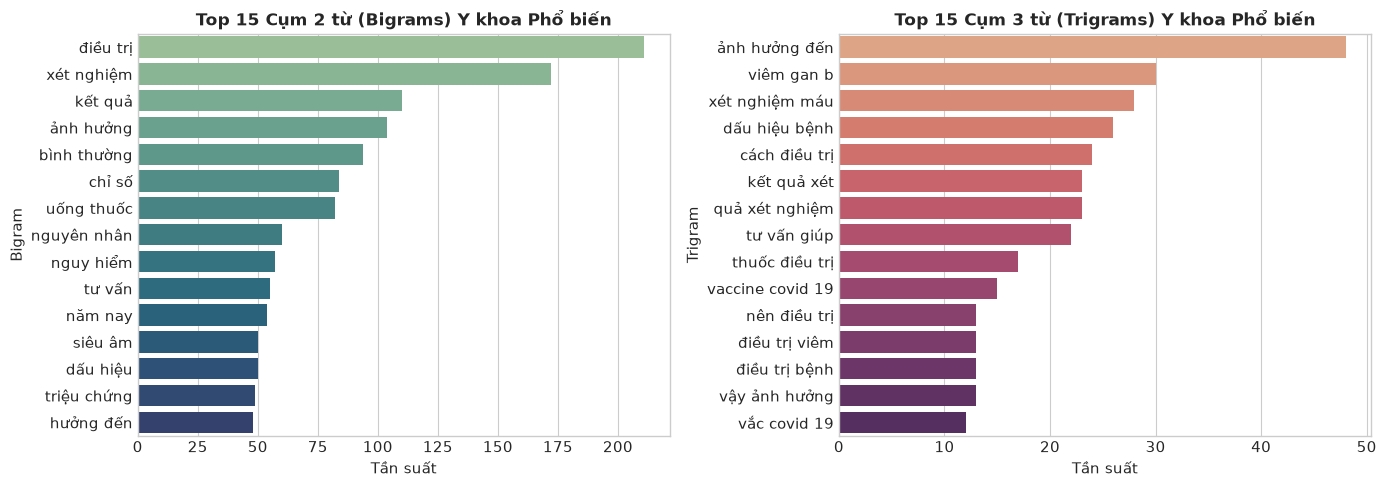

In [8]:
# 2.4 Trích xuất Top N-Grams Y khoa xuất hiện nhiều nhất trong Queries
from collections import Counter

STOPWORDS_VI = {
    "là", "và", "có", "không", "cho", "em", "bị", "gì", "thì", "được", "của", "tôi", "này",
    "đã", "ở", "hay", "khi", "như", "một", "trong", "thế", "nào", "sau", "với", "hỏi", "bác",
    "sĩ", "xin", "ạ", "dạ", "cho", "vừa", "thấy", "lại", "do", "làm", "sao", "đi", "ngày",
}

def extract_ngrams(texts, n=2):
    ngrams = []
    for t in texts:
        tokens = [w.lower() for w in re.findall(r"\b\w+\b", t) if w.lower() not in STOPWORDS_VI]
        for i in range(len(tokens) - n + 1):
            ngrams.append(" ".join(tokens[i:i+n]))
    return Counter(ngrams)

top_bigrams = extract_ngrams(df_queries["query"], n=2).most_common(15)
top_trigrams = extract_ngrams(df_queries["query"], n=3).most_common(15)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
df_bi = pd.DataFrame(top_bigrams, columns=["Bigram", "Tần suất"])
sns.barplot(data=df_bi, y="Bigram", x="Tần suất", ax=axes[0], palette="crest")
axes[0].set_title("Top 15 Cụm 2 từ (Bigrams) Y khoa Phổ biến")

df_tri = pd.DataFrame(top_trigrams, columns=["Trigram", "Tần suất"])
sns.barplot(data=df_tri, y="Trigram", x="Tần suất", ax=axes[1], palette="flare")
axes[1].set_title("Top 15 Cụm 3 từ (Trigrams) Y khoa Phổ biến")

plt.tight_layout()
plt.show()


## 3. Cấu trúc & Hình thái Văn bản Y học (Document Content Anatomy)
Hệ thống crawler của chúng ta đã bóc tách dữ liệu theo các **Content Archetypes** riêng biệt:
1. **Bách khoa bệnh học (Disease Encyclopedia)**: Lưu giữ các thẻ tiêu đề Markdown `## TRIỆU CHỨNG`, `## NGUYÊN NHÂN`, `## ĐIỀU TRỊ` (từ Nhà thuốc Long Châu, Sức Khỏe Đời Sống, Vinmec, Medlatec).
2. **Hỏi đáp Bác sĩ - Bệnh nhân (Q&A)**: Giữ nguyên cặp câu hỏi và lời tư vấn của bác sĩ (từ 120ask, 39.net, YouMed, HelloBacsi).
3. **Bài báo Y khoa Khoa học (PubMed)**: Có cấu trúc chuẩn `## BACKGROUND`, `## METHODS`, `## RESULTS`, `## CONCLUSION`.

Ta sẽ đo lường độ dài văn bản và mức độ phong phú của cấu trúc Markdown trên tập dữ liệu đã cào.


In [9]:
# 3.1 Lấy mẫu đại diện các bài viết đã cào từ shards và PubMed
sample_articles = []

# Mẫu 500 bài tiếng Việt từ shards gần nhất
latest_shards = sorted(shard_files, key=lambda p: p.stat().st_mtime, reverse=True)[:5]
for sf in latest_shards:
    with open(sf, "r", encoding="utf-8") as fp:
        for i, line in enumerate(fp):
            if i >= 100:
                break
            if line.strip():
                sample_articles.append(json.loads(line))

# Mẫu 500 bài tiếng Anh từ PubMed
for pf in pubmed_dir.glob("*.jsonl"):
    with open(pf, "r", encoding="utf-8") as fp:
        for i, line in enumerate(fp):
            if i >= 500:
                break
            if line.strip():
                sample_articles.append(json.loads(line))

df_samples = pd.DataFrame(sample_articles)
df_samples["char_count"] = df_samples["text"].str.len()
df_samples["word_count"] = df_samples["text"].str.split().str.len()
df_samples["has_headings"] = df_samples["text"].str.contains(r"(?m)^#{1,4}\s")
df_samples["num_headings"] = df_samples["text"].apply(lambda t: len(re.findall(r"(?m)^#{1,4}\s", t)))

print(f"Tổng số bài mẫu phân tích: {len(df_samples):,}")
display(df_samples[["domain", "title", "lang", "char_count", "word_count", "num_headings"]].head(8))


Tổng số bài mẫu phân tích: 1,000


,domain,title,lang,char_count,word_count,num_headings
0,suckhoecongdongonline.vn,Video máy xúc cán người dân tại Hải Dương ngày...,vi,272,59,2
1,suckhoecongdongonline.vn,"Video: Máy bay Vietjet bị sự cố khi tiếp đất, ...",vi,367,81,2
2,suckhoecongdongonline.vn,Video minh họa vụ máy bay Nga suýt đâm vào máy...,vi,445,97,2
3,suckhoecongdongonline.vn,Video: Mưa đá to bằng quả trứng gà trút xuống ...,vi,315,66,2
4,suckhoecongdongonline.vn,Video: Mẹ 'cai nghiện' điện thoại cho con nhỏ ...,vi,295,64,2
5,suckhoecongdongonline.vn,"Video nam sinh túm tóc, đánh dã man vào đầu nữ...",vi,319,72,2
6,suckhoecongdongonline.vn,"VIDEO: MU hủy diệt Southampton, 9 bàn lưu danh...",vi,355,75,2
7,suckhoecongdongonline.vn,"VIDEO: Nam thanh niên bất ngờ dừng xe, kéo xền...",vi,363,80,2


/tmp/ipykernel_28629/2082833467.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_samples, x="lang", y="word_count", ax=axes[0], palette="Set2")
/tmp/ipykernel_28629/2082833467.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=heading_pct.index, y=heading_pct.values, ax=axes[1], palette="pastel")


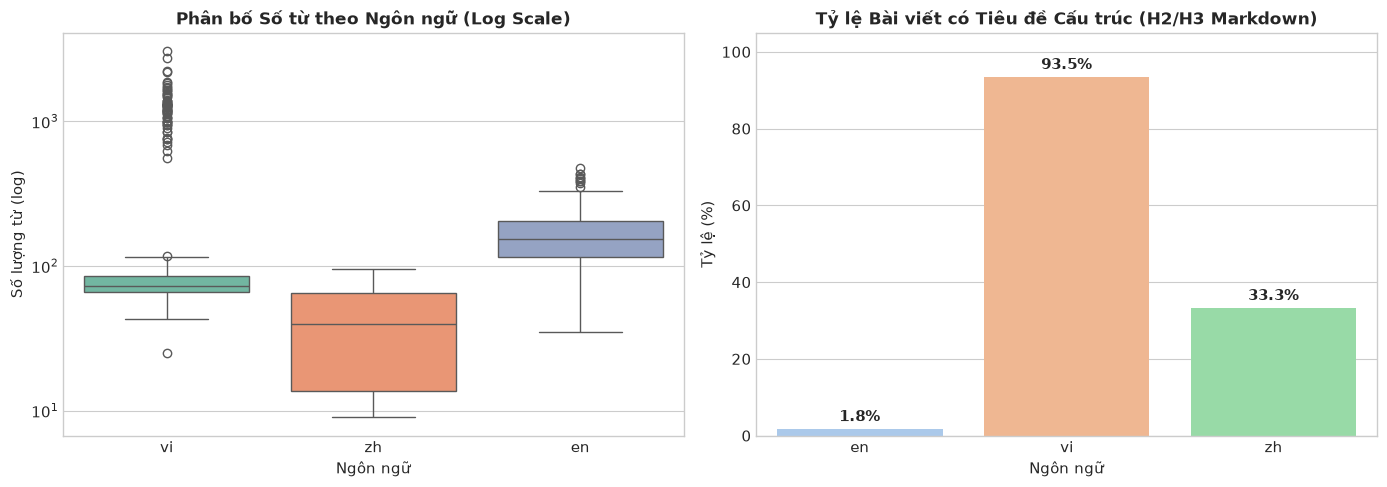

In [10]:
# 3.2 Phân bố độ dài bài viết theo Ngôn ngữ & Nguồn dữ liệu
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.boxplot(data=df_samples, x="lang", y="word_count", ax=axes[0], palette="Set2")
axes[0].set_title("Phân bố Số từ theo Ngôn ngữ (Log Scale)")
axes[0].set_yscale("log")
axes[0].set_xlabel("Ngôn ngữ")
axes[0].set_ylabel("Số lượng từ (log)")

heading_pct = df_samples.groupby("lang")["has_headings"].mean() * 100
sns.barplot(x=heading_pct.index, y=heading_pct.values, ax=axes[1], palette="pastel")
axes[1].set_title("Tỷ lệ Bài viết có Tiêu đề Cấu trúc (H2/H3 Markdown)")
axes[1].set_xlabel("Ngôn ngữ")
axes[1].set_ylabel("Tỷ lệ (%)")
for idx, v in enumerate(heading_pct.values):
    axes[1].text(idx, v + 2, f"{v:.1f}%", ha="center", fontweight="bold")
axes[1].set_ylim(0, 105)

plt.tight_layout()
plt.show()


## 4. Ánh xạ Tri thức Y khoa & Phân loại WHO ICD-10
Theo định hướng của BTC trong buổi **Mentor Day 1**:
- Hệ thống phân loại bệnh học **WHO ICD-10** (22 chương từ I đến XXII) là khung xương sống (backbone) để phân nhóm chủ đề y tế.
- Việc xác định chương ICD-10 của query và document giúp:
  1. **Topic-conditioned Retrieval / Domain Filtering**: Giảm mạnh không gian tìm kiếm, loại trừ các tài liệu hoàn toàn sai chuyên khoa (ví dụ: query hỏi về dạ dày thì không cần search sang tài liệu nhãn khoa hay da liễu).
  2. **Đánh giá mức độ bao phủ (Coverage alignment)**: Đảm bảo tập dữ liệu thu thập không bị thiếu hụt các chuyên khoa mà người dùng hay hỏi.


In [11]:
# 4.1 Khởi tạo ICD-10 Multilingual Tagger
tagger = ICD10Tagger()
print(f"ICD-10 Ontology loaded: {len(tagger.entries):,} entries across 22 chapters.")

# Gán nhãn ICD-10 cho toàn bộ 1,200 Queries
query_tags = []
for q in tqdm(df_queries["query"], desc="Gán nhãn ICD-10 cho Queries"):
    res = tagger.tag(q, lang="vi")
    query_tags.append(res.primary_chapter or "Unmatched / General")

df_queries["icd10_chapter"] = query_tags
query_chapter_counts = Counter(query_tags)

print("\nTop các Chương ICD-10 xuất hiện nhiều nhất trong 1,200 Queries:")
for ch, count in query_chapter_counts.most_common(10):
    print(f" - {ch:45s}: {count:4d} queries ({count/len(df_queries)*100:.1f}%)")


2026-10-21 23:45:19.505 | WARNING  | src.ingestion.icd10_tagger:_load_ontology:122 - ICD-10 ontology file not found at data/lexicon/icd10_ontology.json


ICD-10 Ontology loaded: 0 entries across 22 chapters.



Gán nhãn ICD-10 cho Queries:   0%|                    | 0/1200 [00:00<?, ?it/s]


Gán nhãn ICD-10 cho Queries: 100%|██████| 1200/1200 [00:00<00:00, 30411.69it/s]


Top các Chương ICD-10 xuất hiện nhiều nhất trong 1,200 Queries:
 - Unmatched / General                          :  375 queries (31.2%)
 - (XVIII) R00-R99: Triệu chứng, dấu hiệu và kết quả lâm sàng:  142 queries (11.8%)
 - (XI) K00-K93: Bệnh hệ tiêu hóa               :  130 queries (10.8%)
 - (XIV) N00-N99: Bệnh hệ tiết niệu, sinh dục   :   81 queries (6.8%)
 - (X) J00-J99: Bệnh hệ hô hấp                  :   66 queries (5.5%)
 - (XV) O00-O99: Thai nghén, sinh đẻ và hậu sản :   54 queries (4.5%)
 - (VI) G00-G99: Bệnh hệ thần kinh              :   51 queries (4.2%)
 - (XII) L00-L99: Bệnh của da và mô dưới da     :   50 queries (4.2%)
 - (XIII) M00-M99: Bệnh hệ cơ, xương, khớp      :   46 queries (3.8%)
 - (VII) H00-H59: Bệnh của mắt và phần phụ      :   40 queries (3.3%)



Gán nhãn ICD-10 cho Corpus Sample:   0%|              | 0/1000 [00:00<?, ?it/s]


Gán nhãn ICD-10 cho Corpus Sample: 100%|█| 1000/1000 [00:00<00:00, 18795.73it/s

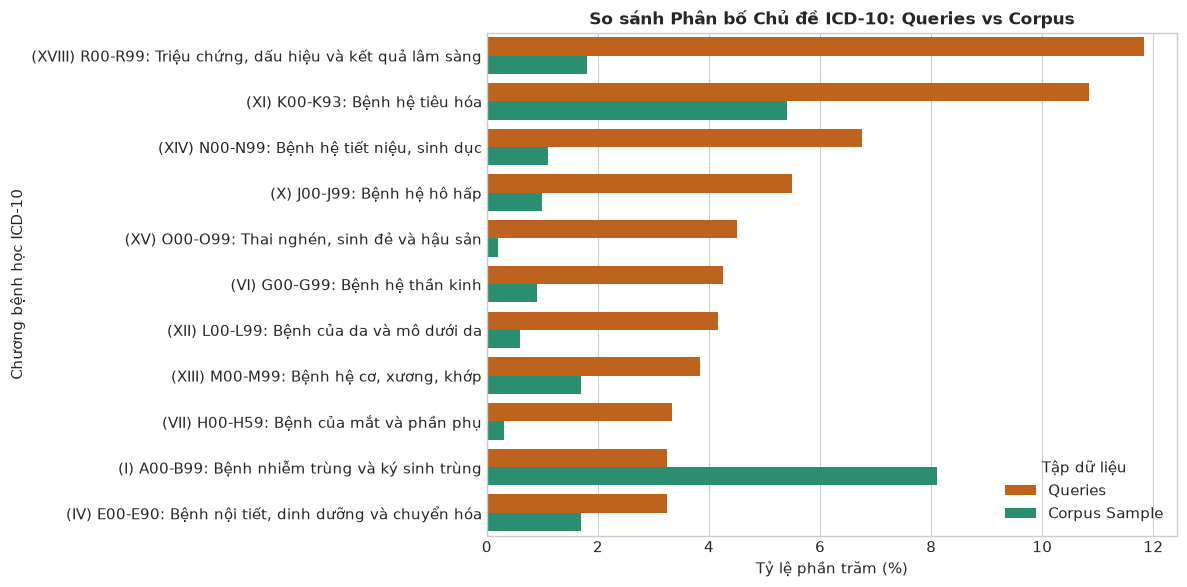

In [12]:
# 4.2 Gán nhãn ICD-10 cho tập mẫu tài liệu và so sánh phân bổ
corpus_tags = []
for text in tqdm(df_samples["text"], desc="Gán nhãn ICD-10 cho Corpus Sample"):
    res = tagger.tag(text[:3000])  # Dùng 3,000 ký tự đầu để nhận diện chủ đề
    corpus_tags.append(res.primary_chapter or "Unmatched / General")

df_samples["icd10_chapter"] = corpus_tags
corpus_chapter_counts = Counter(corpus_tags)

# Chuẩn bị dữ liệu so sánh
top_chapters = [ch for ch, _ in query_chapter_counts.most_common(12) if ch != "Unmatched / General"]
df_compare = pd.DataFrame({
    "Chapter": top_chapters,
    "Query_Pct": [query_chapter_counts[ch] / len(df_queries) * 100 for ch in top_chapters],
    "Corpus_Pct": [corpus_chapter_counts[ch] / len(df_samples) * 100 for ch in top_chapters],
})

fig, ax = plt.subplots(figsize=(12, 6))
df_compare_melted = df_compare.melt(id_vars="Chapter", var_name="Tập dữ liệu", value_name="Tỷ lệ (%)")
df_compare_melted["Tập dữ liệu"] = df_compare_melted["Tập dữ liệu"].map({"Query_Pct": "Queries", "Corpus_Pct": "Corpus Sample"})

sns.barplot(data=df_compare_melted, y="Chapter", x="Tỷ lệ (%)", hue="Tập dữ liệu", palette=["#d95f02", "#1b9e77"], ax=ax)
ax.set_title("So sánh Phân bố Chủ đề ICD-10: Queries vs Corpus")
ax.set_xlabel("Tỷ lệ phần trăm (%)")
ax.set_ylabel("Chương bệnh học ICD-10")
plt.tight_layout()
plt.show()


## 5. Khoảng cách Ngữ nghĩa Đa ngữ (Cross-Lingual Semantic Gap)
Thách thức cốt lõi của ViBioMIR:
- **Truy vấn**: 100% Tiếng Việt (ngôn ngữ đời thường, giàu sắc thái cảm xúc, mô tả triệu chứng dân gian).
- **Corpus**: Tiếng Việt (~60%), Tiếng Anh học thuật PubMed (~20%), Tiếng Trung tư vấn y tế (~20%).
- Nếu chỉ dùng thuật toán khớp từ truyền thống (Lexical / BM25 / TF-IDF):
  - **Khớp tốt** trên tập tài liệu tiếng Việt có chung từ vựng.
  - **Điểm 0 tuyệt đối** trên tài liệu tiếng Anh (PubMed) và tiếng Trung (120ask), vì hai bên không chia sẻ bất kỳ token từ ngữ nào!
Ta sẽ minh họa trực quan sự thiếu hụt này.


/tmp/ipykernel_28629/773981490.py:21: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=overlap_by_lang.index, y=overlap_by_lang.values, palette=["#2ca02c", "#1f77b4", "#d62728"], ax=ax)


🔍 Câu truy vấn kiểm thử:
'Em bị viêm xung huyết 1/3 dưới thực quản, viêm dạ dày trợt xung huyết mạn tính, sẹo loét hành tá tràng. Cho em hỏi các bệnh này của em có nặng và có thể khỏi được không. Em vừa uống xong đợt thuốc được 1 2 ngày thì giờ em lại thấy triệu chứng bị nghẹn ở cổ và hơi buồn nôn. không biết có phải bệnh nặng lên hay do sao.'

Số lượng từ trùng lặp trung bình với query tiếng Việt:
 - Tài liệu EN: 0.94 từ trùng khớp
 - Tài liệu VI: 8.66 từ trùng khớp
 - Tài liệu ZH: 1.67 từ trùng khớp


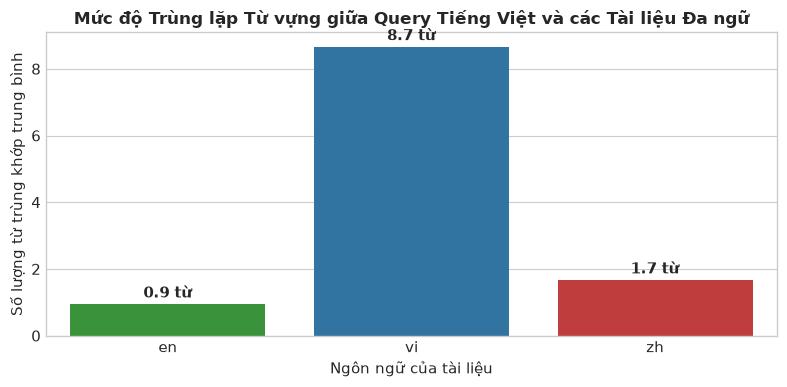

In [13]:
# 5.1 Thử nghiệm tìm kiếm từ vựng (Lexical Overlap Test)
# Lấy ví dụ một query y khoa thực tế:
sample_q = df_queries.iloc[0]["query"]
print("🔍 Câu truy vấn kiểm thử:")
print(f"'{sample_q}'")

q_tokens = set(re.findall(r"\b\w+\b", sample_q.lower()))

def count_overlap(text):
    text_tokens = set(re.findall(r"\b\w+\b", text.lower()))
    return len(q_tokens.intersection(text_tokens))

df_samples["lexical_overlap"] = df_samples["text"].apply(count_overlap)

overlap_by_lang = df_samples.groupby("lang")["lexical_overlap"].mean()
print("\nSố lượng từ trùng lặp trung bình với query tiếng Việt:")
for l, val in overlap_by_lang.items():
    print(f" - Tài liệu {l.upper()}: {val:.2f} từ trùng khớp")

fig, ax = plt.subplots(figsize=(8, 4))
sns.barplot(x=overlap_by_lang.index, y=overlap_by_lang.values, palette=["#2ca02c", "#1f77b4", "#d62728"], ax=ax)
ax.set_title("Mức độ Trùng lặp Từ vựng giữa Query Tiếng Việt và các Tài liệu Đa ngữ")
ax.set_xlabel("Ngôn ngữ của tài liệu")
ax.set_ylabel("Số lượng từ trùng khớp trung bình")
for idx, v in enumerate(overlap_by_lang.values):
    ax.text(idx, v + 0.2, f"{v:.1f} từ", ha="center", fontweight="bold")
plt.tight_layout()
plt.show()


### 💡 Bài học then chốt (Key Takeaway):
1. **Lexical (BM25)** chỉ có tác dụng đối với tài liệu Tiếng Việt.
2. Để truy hồi tài liệu Tiếng Anh (PubMed) và Tiếng Trung, hệ thống bắt buộc phải sử dụng **Dense Cross-Lingual Embeddings** (như mô hình đa ngữ `BAAI/bge-m3` có khả năng biểu diễn 100+ ngôn ngữ trong cùng một không gian vector ngữ nghĩa).
3. Kiến trúc tối ưu là **Hybrid Retrieval**:
   $$\text{Score} = \alpha \cdot \text{Dense\_Score}(\text{BGE-M3}) + (1 - \alpha) \cdot \text{BM25\_Score}$$
   kết hợp cùng **Cross-Encoder Reranker** (`BAAI/bge-reranker-v2-m3`).


## 6. Chiến lược Phân đoạn (Chunking) & Tác động tới Thang đo F2
Quy chế cuộc thi đánh giá ở 2 cấp độ:
1. **Document Retrieval**: Tìm đúng tài liệu ($D$).
2. **Chunk Retrieval**: Định vị đúng đoạn nội dung gốc ($C$).

Thang đo chính là **$F_2$-Score**:
$$F_2 = 5 \times \frac{\text{Precision} \times \text{Recall}}{4 \cdot \text{Precision} + \text{Recall}}$$

> [!IMPORTANT]
> **Ý nghĩa của $F_2$-Score**: Thang đo $F_2$ gán trọng số cho **Recall gấp 2 lần Precision**!
> Điều này có nghĩa: Hệ thống chấp nhận lấy dư một chút ứng viên (False Positive) để không bỏ sót tài liệu đúng (False Negative).
> Khi thiết kế retrieval, chiến lược hàng đầu là:
> - Tăng số lượng ứng viên ở pha检索 (Top-50 hoặc Top-100 candidates).
> - Phân đoạn văn bản (Chunking) theo kích thước phù hợp (256 - 512 tokens) với độ chồng lấn (overlap 50-100 tokens) để bảo toàn đầy đủ ngữ cảnh y khoa.


Tài liệu gốc: 59 từ.
 - Chiến lược 1: Sliding Window (250 từ, overlap 50 từ) ➔ 1 chunks.
 - Chiến lược 2: Heading-Aware (Cắt theo cấu trúc H2/H3) ➔ 2 chunks.


/tmp/ipykernel_28629/3667345557.py:33: UserWarning: Dataset has 0 variance; skipping density estimate. Pass `warn_singular=False` to disable this warning.
  sns.kdeplot(lengths_sliding, label=f"Sliding Window (Mean: {np.mean(lengths_sliding):.0f} từ)", fill=True, ax=ax)


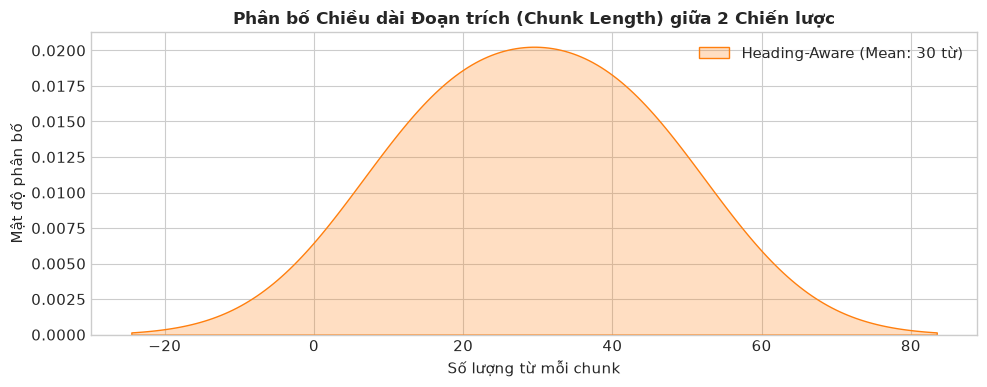

In [14]:
# 6.1 Mô phỏng các chiến lược Chunking trên tài liệu mẫu
def chunk_by_words(text, chunk_size=300, overlap=50):
    words = text.split()
    chunks = []
    i = 0
    while i < len(words):
        chunk = " ".join(words[i:i + chunk_size])
        chunks.append(chunk)
        i += chunk_size - overlap
        if i >= len(words) - overlap and i < len(words):
            break
    return chunks

def chunk_by_headings(text):
    # Chia theo các tiêu đề H2/H3
    sections = re.split(r"(?m)(?=^#{1,3}\s)", text)
    return [s.strip() for s in sections if len(s.strip()) > 50]

sample_docs_with_h = df_samples[df_samples["has_headings"]]
sample_doc = sample_docs_with_h.iloc[0]["text"] if len(sample_docs_with_h) > 0 else df_samples.iloc[0]["text"]
sliding_chunks = chunk_by_words(sample_doc, chunk_size=250, overlap=50)
heading_chunks = chunk_by_headings(sample_doc)

print(f"Tài liệu gốc: {len(sample_doc.split()):,} từ.")
print(f" - Chiến lược 1: Sliding Window (250 từ, overlap 50 từ) ➔ {len(sliding_chunks)} chunks.")
print(f" - Chiến lược 2: Heading-Aware (Cắt theo cấu trúc H2/H3) ➔ {len(heading_chunks)} chunks.")

# Minh họa độ dài các chunk sinh ra
fig, ax = plt.subplots(figsize=(10, 4))
lengths_sliding = [len(c.split()) for c in sliding_chunks]
lengths_heading = [len(c.split()) for c in heading_chunks]

sns.kdeplot(lengths_sliding, label=f"Sliding Window (Mean: {np.mean(lengths_sliding):.0f} từ)", fill=True, ax=ax)
sns.kdeplot(lengths_heading, label=f"Heading-Aware (Mean: {np.mean(lengths_heading):.0f} từ)", fill=True, ax=ax)
ax.set_title("Phân bố Chiều dài Đoạn trích (Chunk Length) giữa 2 Chiến lược")
ax.set_xlabel("Số lượng từ mỗi chunk")
ax.set_ylabel("Mật độ phân bố")
ax.legend()
plt.tight_layout()
plt.show()


## 7. Tổng kết Insights & Khuyến nghị Kỹ thuật cho Pipeline

Dưới đây là bảng tổng hợp các đặc tính cốt lõi của dữ liệu và giải pháp tương ứng cho hệ thống Retrieval:

| Đặc tính Dữ liệu | Thách thức Thực tế | Giải pháp & Định hướng Pipeline |
| :--- | :--- | :--- |
| **Corpus 1.19M Đa ngữ (VI, EN, ZH)** | Khác biệt token, BM25 hoàn toàn bất lực khi query tiếng Việt tìm tài liệu PubMed / tiếng Trung | Sử dụng **Dense Retrieval (BGE-M3)** đa ngữ kết hợp **BM25** cho tiếng Việt (Hybrid Retrieval). |
| **Thang đo $F_2$-Score** | Phạt nặng việc bỏ sót tài liệu (Recall được ưu tiên gấp đôi Precision) | Cấu hình Top-k ứng viên lớn ở First-stage (Top 50 - 100), sau đó dùng Cross-Encoder Reranker lọc lại Top 10. |
| **Cấu trúc Y khoa giàu H2/H3** | Cắt đoạn ngây thơ (naive chunking) làm đứt gãy quan hệ giữa bệnh và triệu chứng/thuốc | Áp dụng **Heading-aware Chunking**: Tiền tố `[Tiêu đề bài viết] > [Tên mục H2]` được đính kèm vào mỗi chunk. |
| **22 Chương WHO ICD-10** | Không gian tìm kiếm 1.2M tài liệu quá lớn, dễ gây nhiễu chéo chuyên khoa | Sử dụng **ICD-10 Tagger** để phân loại Query và Document, hỗ trợ lọc chủ đề (Category Routing). |
| **Dạng bài Hỏi-Đáp (Q&A)** | Câu hỏi bệnh nhân dài dòng, câu trả lời bác sĩ nằm rải rác | Ghép cặp Question + Doctor Answer vào cùng một chunk hoàn chỉnh. |

---
**Notebook hoàn tất! Bạn có thể tiếp tục triển khai các mô hình embedding và indexing trên Kaggle/Colab theo cấu trúc khuyến nghị ở trên.**
